<a href="https://colab.research.google.com/github/magicpoopi/Clustering/blob/main/Copy_of_Untitled20.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

# STEP 1 : IMPORT LIBRARIES


import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler

from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering

from sklearn.metrics import silhouette_score

from sklearn.decomposition import PCA

from scipy.cluster.hierarchy import dendrogram, linkage

plt.rcParams["figure.figsize"]=(8,5)

In [ ]:

# STEP 2 : UPLOAD DATASET


print("Click the Upload button and select your CSV file")

uploaded = files.upload()

filename = list(uploaded.keys())[0]

df = pd.read_csv(filename)

print("\nDataset Loaded Successfully")
print("File Name :", filename)

df.head()

Click the Upload button and select your CSV file


Saving Document from AdrijaNair to Document from AdrijaNair

Dataset Loaded Successfully
File Name : Document from AdrijaNair


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [ ]:

# STEP 3 : DATASET INFORMATION

print("Shape of Dataset")
print(df.shape)

print("\nColumns")
print(df.columns)

print("\nInformation")
df.info()

print("\nFirst 5 Rows")
display(df.head())

print("\nLast 5 Rows")
display(df.tail())

Shape of Dataset
(48842, 15)

Columns
Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country',
       'income'],
      dtype='object')

Information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K



Last 5 Rows


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
48837,39.0,Private,215419,Bachelors,13,Divorced,Prof-specialty,Not-in-family,White,Female,0,0,36.0,United-States,<=50K.
48838,64.0,NaN,321403,HS-grad,9,Widowed,NaN,Other-relative,Black,Male,0,0,40.0,United-States,<=50K.
48839,38.0,Private,374983,Bachelors,13,Married-civ-spouse,Prof-specialty,Husband,White,Male,0,0,50.0,United-States,<=50K.
48840,44.0,Private,83891,Bachelors,13,Divorced,Adm-clerical,Own-child,Asian-Pac-Islander,Male,5455,0,40.0,United-States,<=50K.
48841,35.0,Self-emp-inc,182148,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,60.0,United-States,>50K.


In [ ]:

# STEP 4 : CHECK MISSING VALUES


df.replace(" ?", np.nan, inplace=True)
df.replace("?", np.nan, inplace=True)

print("Missing Values")
print(df.isnull().sum())

Missing Values
age               2442
workclass         5125
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        5115
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    3260
income               0
dtype: int64


In [ ]:

# STEP 5 : HANDLE MISSING VALUES


for column in df.columns:

    if df[column].dtype == "object":

        df[column].fillna(df[column].mode()[0], inplace=True)

    else:

        df[column].fillna(df[column].median(), inplace=True)

print("Missing Values After Filling")

print(df.isnull().sum())

Missing Values After Filling
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
income            0
dtype: int64


/tmp/ipykernel_350/3217938158.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df[column].fillna(df[column].median(), inplace=True)
/tmp/ipykernel_350/3217938158.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', t

In [ ]:

# STEP 6 : DROP INCOME COLUMN


if "income" in df.columns:
    df = df.drop("income", axis=1)

elif "Income" in df.columns:
    df = df.drop("Income", axis=1)

elif "salary" in df.columns:
    df = df.drop("salary", axis=1)

print("Columns after dropping income")
print(df.columns)

Columns after dropping income
Index(['age', 'workclass', 'fnlwgt', 'education', 'education-num',
       'marital-status', 'occupation', 'relationship', 'race', 'sex',
       'capital-gain', 'capital-loss', 'hours-per-week', 'native-country'],
      dtype='object')


In [ ]:

# STEP 7 : ENCODE CATEGORICAL VARIABLES

label_encoder = LabelEncoder()

categorical_columns = df.select_dtypes(include=["object"]).columns

for column in categorical_columns:

    df[column] = label_encoder.fit_transform(df[column])

print("Encoding Completed")

df.head()

Encoding Completed


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39.0,6,77516,9,13,4,0,1,4,1,2174,0,40.0,38
1,50.0,5,83311,9,13,2,3,0,4,1,0,0,13.0,38
2,38.0,3,215646,11,9,0,5,1,4,1,0,0,40.0,38
3,53.0,3,234721,1,7,2,5,0,2,1,0,0,40.0,38
4,28.0,3,338409,9,13,2,9,5,2,0,0,0,40.0,4


In [ ]:

# STEP 8 : REMOVE OUTLIERS USING IQR

numeric_columns = df.select_dtypes(include=np.number).columns

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)

    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    df[column] = np.where(df[column] < lower, lower, df[column])

    df[column] = np.where(df[column] > upper, upper, df[column])

print("Outliers Treated Successfully")

Outliers Treated Successfully


In [ ]:

# STEP 9 : FEATURE SCALING


scaler = StandardScaler()

scaled_data = scaler.fit_transform(df)

scaled_df = pd.DataFrame(scaled_data, columns=df.columns)

scaled_df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,0.035311,0.0,-1.146097,-0.497024,1.171374,0.916138,-1.607439,-0.276685,0.0,0.70422,0.0,0.0,-0.187236,0.0
1,0.864184,0.0,-1.085307,-0.497024,1.171374,-0.410397,-0.841761,-0.900852,0.0,0.70422,0.0,0.0,-1.430298,0.0
2,-0.040041,0.0,0.302906,0.127117,-0.456714,-1.736932,-0.331310,-0.276685,0.0,0.70422,0.0,0.0,-0.187236,0.0
3,1.090241,0.0,0.503005,-1.901342,-1.270758,-0.410397,-0.331310,-0.900852,0.0,0.70422,0.0,0.0,-0.187236,0.0
4,-0.793562,0.0,1.590706,-0.497024,1.171374,-0.410397,0.689594,2.219984,0.0,-1.42001,0.0,0.0,-0.187236,0.0


In [ ]:

# STEP 10 : EXPLORATORY DATA ANALYSIS (EDA)


print("Statistical Summary")
display(df.describe())

Statistical Summary


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
count,48842.000000,48842.0,48842.000000,48842.000000,48842.000000,48842.000000,48842.000000,48842.000000,48842.0,48842.000000,48842.0,48842.0,48842.000000,48842.0
mean,38.531387,3.0,186770.707163,10.592666,10.122088,2.618750,6.298104,1.443287,4.0,0.668482,0.0,0.0,41.129683,38.0
std,13.271160,0.0,95328.614282,3.204437,2.456895,1.507703,3.918138,1.602151,0.0,0.470764,0.0,0.0,6.033548,0.0
min,17.000000,3.0,12285.000000,4.500000,4.500000,0.000000,0.000000,0.000000,4.0,0.000000,0.0,0.0,32.500000,38.0
25%,28.000000,3.0,117550.500000,9.000000,9.000000,2.000000,3.000000,0.000000,4.0,0.000000,0.0,0.0,40.000000,38.0
50%,37.000000,3.0,178144.500000,11.000000,10.000000,2.000000,7.000000,1.000000,4.0,1.000000,0.0,0.0,40.000000,38.0
75%,47.000000,3.0,237642.000000,12.000000,12.000000,4.000000,9.000000,3.000000,4.0,1.000000,0.0,0.0,45.000000,38.0
max,75.500000,3.0,417779.250000,15.000000,16.000000,6.000000,13.000000,5.000000,4.0,1.000000,0.0,0.0,52.500000,38.0


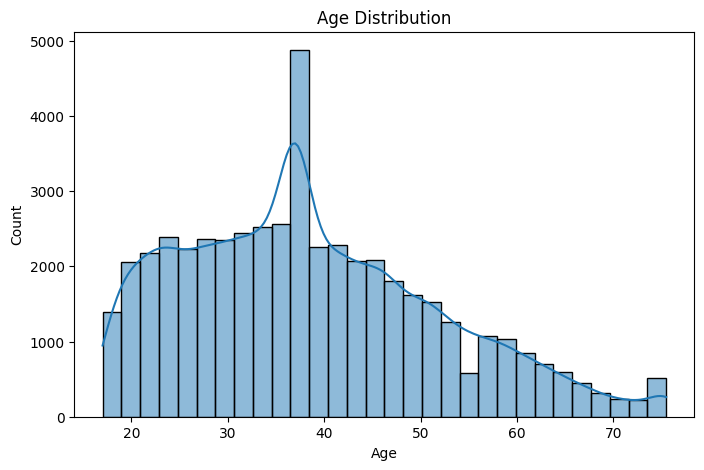

In [ ]:

# AGE DISTRIBUTION


plt.figure(figsize=(8,5))
sns.histplot(df["age"], bins=30, kde=True)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

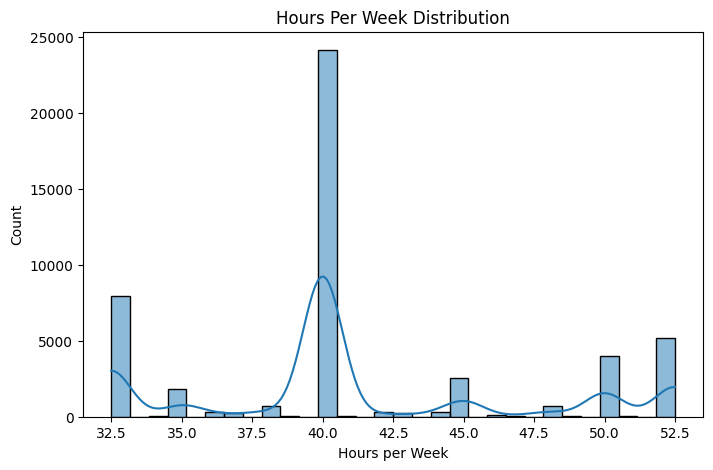

In [ ]:

# HOURS PER WEEK DISTRIBUTION


plt.figure(figsize=(8,5))
sns.histplot(df["hours-per-week"], bins=30, kde=True)
plt.title("Hours Per Week Distribution")
plt.xlabel("Hours per Week")
plt.ylabel("Count")
plt.show()

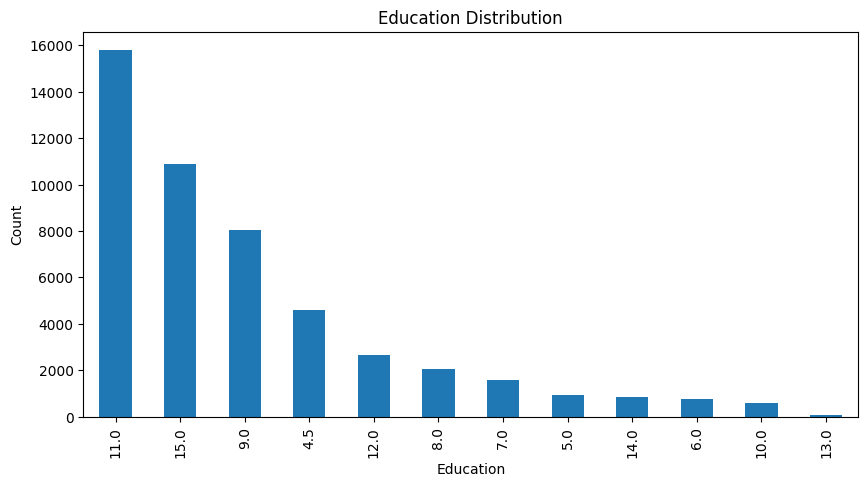

In [ ]:

# EDUCATION DISTRIBUTION


plt.figure(figsize=(10,5))
df["education"].value_counts().plot(kind="bar")
plt.title("Education Distribution")
plt.xlabel("Education")
plt.ylabel("Count")
plt.show()

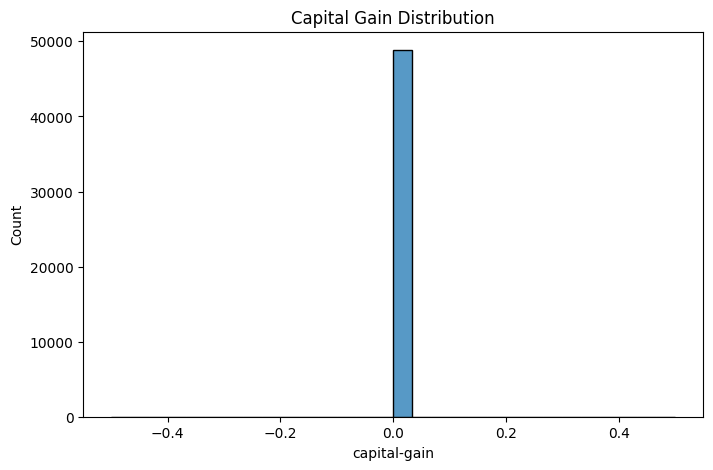

In [ ]:

# CAPITAL GAIN DISTRIBUTION


plt.figure(figsize=(8,5))
sns.histplot(df["capital-gain"], bins=30)
plt.title("Capital Gain Distribution")
plt.show()

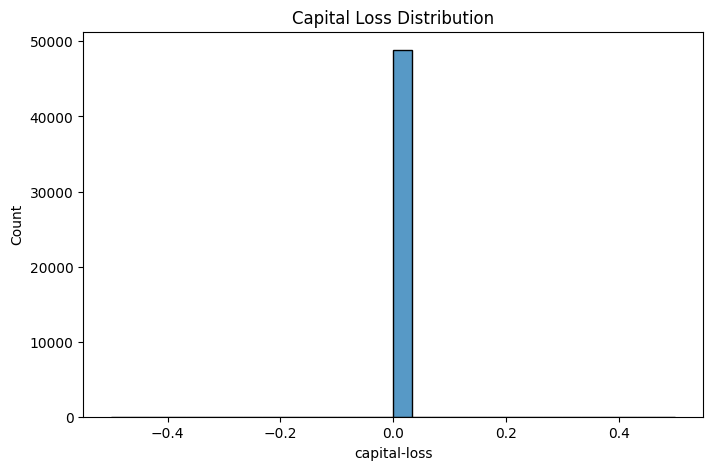

In [ ]:

# CAPITAL LOSS DISTRIBUTION


plt.figure(figsize=(8,5))
sns.histplot(df["capital-loss"], bins=30)
plt.title("Capital Loss Distribution")
plt.show()

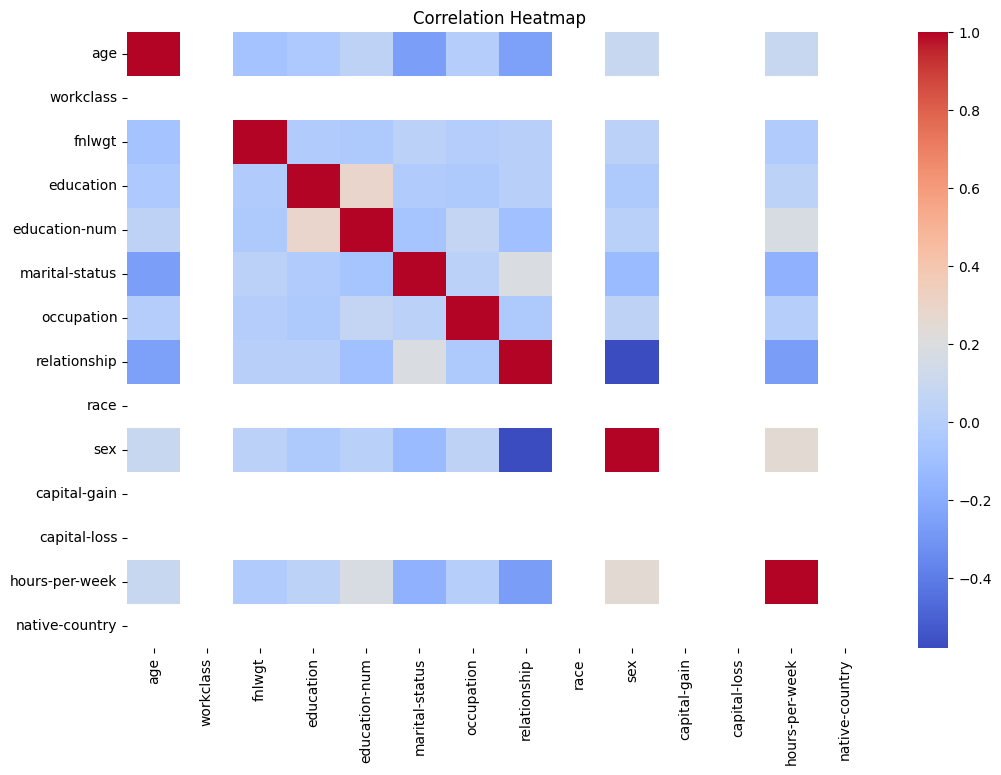

In [ ]:

# CORRELATION HEATMAP


plt.figure(figsize=(12,8))
sns.heatmap(df.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

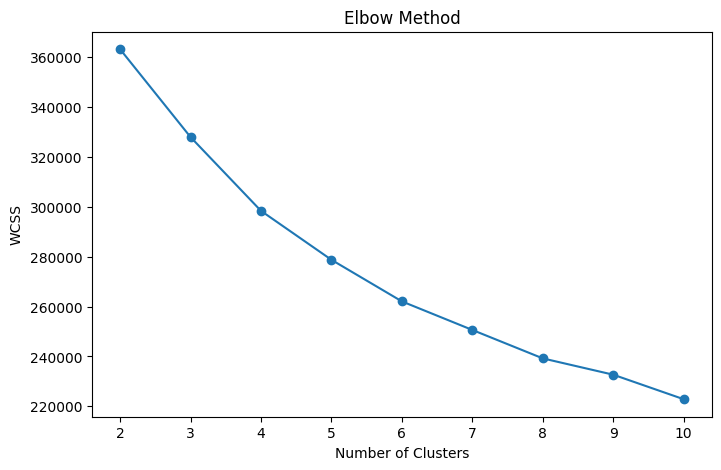

In [ ]:

# STEP 11 : ELBOW METHOD


wcss = []

for i in range(2,11):

    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)

    kmeans.fit(scaled_df)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8,5))
plt.plot(range(2,11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [ ]:

# STEP 12 : SILHOUETTE SCRORE

for i in range(2,11):

    model = KMeans(n_clusters=i, random_state=42, n_init=10)

    labels = model.fit_predict(scaled_df)

    score = silhouette_score(scaled_df, labels)

    print("Clusters =", i, "Silhouette Score =", score)

Clusters = 2 Silhouette Score = 0.1809324732441119
Clusters = 3 Silhouette Score = 0.1890157096444823
Clusters = 4 Silhouette Score = 0.1871170759151985
Clusters = 5 Silhouette Score = 0.1441946276776027
Clusters = 6 Silhouette Score = 0.1458549859355497
Clusters = 7 Silhouette Score = 0.15839621713673835
Clusters = 8 Silhouette Score = 0.14871862827161605
Clusters = 9 Silhouette Score = 0.1537543654466006
Clusters = 10 Silhouette Score = 0.14786160921806743


In [ ]:

# STEP 13 : K-MEANS CLUSTERING


kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(scaled_df)

scaled_df["KMeans_Cluster"] = kmeans_labels

print("Cluster Counts")

print(scaled_df["KMeans_Cluster"].value_counts())

Cluster Counts
KMeans_Cluster
1    24878
2    17611
0     6353
Name: count, dtype: int64


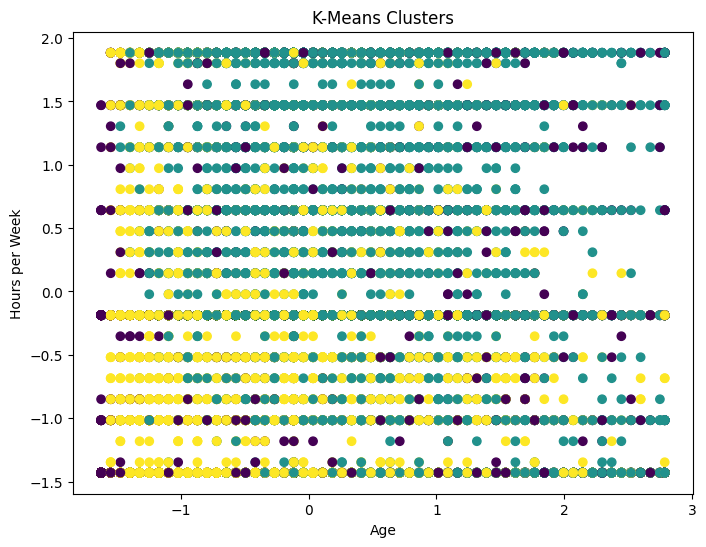

In [ ]:

# K-MEANS CLUSTER VISUALIZATION


plt.figure(figsize=(8,6))

plt.scatter(scaled_df["age"],
            scaled_df["hours-per-week"],
            c=scaled_df["KMeans_Cluster"])

plt.xlabel("Age")
plt.ylabel("Hours per Week")
plt.title("K-Means Clusters")
plt.show()

In [ ]:

# K-MEANS CLUSTER SUMMARY


cluster_summary = scaled_df.groupby("KMeans_Cluster").mean()

display(cluster_summary)

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
KMeans_Cluster,,,,,,,,,,,,,,
0,-0.007685,0.0,0.092410,-1.809238,-1.693733,0.184800,0.066896,0.119057,0.0,0.047190,0.0,0.0,-0.307518,0.0
1,0.281288,0.0,-0.029792,0.204815,0.341861,-0.375178,0.041803,-0.662581,0.0,0.596549,0.0,0.0,0.359493,0.0
2,-0.394587,0.0,0.008750,0.363336,0.128072,0.463327,-0.083185,0.893039,0.0,-0.859732,0.0,0.0,-0.396900,0.0


In [ ]:

# STEP 14 : AGGLOMERATIVE CLUSTERING
# ==

agg = AgglomerativeClustering(n_clusters=3)

agg_labels = agg.fit_predict(scaled_df.drop("KMeans_Cluster", axis=1))

scaled_df["Agglomerative_Cluster"] = agg_labels

print("Agglomerative Cluster Counts")

print(scaled_df["Agglomerative_Cluster"].value_counts())

In [ ]:

# STEP 15 : DENDROGRAM


plt.figure(figsize=(12,6))

link = linkage(scaled_df.drop(["KMeans_Cluster","Agglomerative_Cluster"], axis=1),
               method="ward")

dendrogram(link)

plt.title("Dendrogram")

plt.xlabel("Data Points")

plt.ylabel("Euclidean Distance")

plt.show()

In [ ]:

# STEP 16 : PCA


pca = PCA(n_components=2)

pca_data = pca.fit_transform(
    scaled_df.drop(["KMeans_Cluster","Agglomerative_Cluster"], axis=1)
)

pca_df = pd.DataFrame(pca_data, columns=["PC1","PC2"])

print("Explained Variance Ratio")

print(pca.explained_variance_ratio_)

In [ ]:

# STEP 17 : PCA VISUALIZATION (K-MEANS)


plt.figure(figsize=(8,6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=scaled_df["KMeans_Cluster"]
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization - KMeans")

plt.show()

In [ ]:

# STEP 18 : PCA VISUALIZATION (AGGLOMERATIVE)


plt.figure(figsize=(8,6))

plt.scatter(
    pca_df["PC1"],
    pca_df["PC2"],
    c=scaled_df["Agglomerative_Cluster"]
)

plt.xlabel("Principal Component 1")

plt.ylabel("Principal Component 2")

plt.title("PCA Visualization - Agglomerative")

plt.show()

In [ ]:

# STEP 19 : CLUSTER COMPARISON

comparison = pd.crosstab(
    scaled_df["KMeans_Cluster"],
    scaled_df["Agglomerative_Cluster"]
)

print("Comparison of Clusters")

display(comparison)

In [ ]:

# STEP 20 : CLUSTER CHARACTERISTICS


print("K-Means Cluster Characteristics")

display(
    scaled_df.groupby("KMeans_Cluster").mean()
)

print("Agglomerative Cluster Characteristics")

display(
    scaled_df.groupby("Agglomerative_Cluster").mean()
)

In [ ]:

# STEP 22 : SAVE CLEANED DATASET


scaled_df.to_csv("Cleaned_Clustered_Dataset.csv", index=False)

print("Dataset Saved Successfully")

# STEP 23 : DOWNLOAD CLEANED DATASET


from google.colab import files

files.download("Cleaned_Clustered_Dataset.csv")